In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import io

In [8]:
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
    movies = pd.read_csv(zip_file.open("ml-latest-small/movies.csv"))
    ratings = pd.read_csv(zip_file.open("ml-latest-small/ratings.csv"))
    links = pd.read_csv(zip_file.open("ml-latest-small/links.csv"))
    tags = pd.read_csv(zip_file.open("ml-latest-small/tags.csv"))

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [9]:
print("MOVIES:", movies.shape)
print("RATINGS:", ratings.shape)
print("LINKS:", links.shape)
print("TAGS:", tags.shape)

MOVIES: (9742, 3)
RATINGS: (100836, 4)
LINKS: (9742, 3)
TAGS: (3683, 4)


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os

PROJECT_DIR = "/content/drive/MyDrive/CINEMETRIX"

folders = [
    "data/raw/movielens",
    "data/raw/tmdb",
    "data/raw/imdb",
    "data/processed",
    "data/final",
    "notebooks",
    "sql",
    "powerbi",
    "reports",
    "models"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("CINEMETRIX project folders created!")

CINEMETRIX project folders created!


In [13]:
movielens_data = {
    "movies": movies,
    "ratings": ratings,
    "links": links,
    "tags": tags
}

for name, df in movielens_data.items():
    path = f"{PROJECT_DIR}/data/raw/movielens/{name}.csv"
    df.to_csv(path, index=False)

print("MovieLens datasets saved successfully!")

MovieLens datasets saved successfully!


In [14]:
!pip -q install datasets

In [ ]:
from datasets import load_dataset

tmdb_data = load_dataset(
    "ashen97/TMDB-box-office",
    split="train"
)

tmdb_boxoffice = tmdb_data.to_pandas()

print("TMDB dataset loaded!")
print(tmdb_boxoffice.shape)
print(tmdb_boxoffice.columns.tolist())

In [15]:
tmdb_path = f"{PROJECT_DIR}/data/raw/tmdb/tmdb_boxoffice.csv"

tmdb_boxoffice.to_csv(tmdb_path, index=False)

print("TMDB original dataset saved!")

TMDB original dataset saved!


In [16]:
imdb_url = "https://datasets.imdbws.com/title.ratings.tsv.gz"

imdb_ratings = pd.read_csv(
    imdb_url,
    sep="\t",
    compression="gzip",
    dtype={"tconst": "string"}
)

print("IMDb ratings loaded!")
print(imdb_ratings.shape)

IMDb ratings loaded!
(1729742, 3)


In [17]:
links_imdb = links.dropna(subset=["imdbId"]).copy()

links_imdb["tconst"] = (
    "tt" +
    links_imdb["imdbId"]
    .astype("Int64")
    .astype(str)
    .str.zfill(7)
)

imdb_matched = links_imdb.merge(
    imdb_ratings,
    on="tconst",
    how="left"
)

print("IMDb ratings matched!")
print(imdb_matched.shape)

IMDb ratings matched!
(9742, 6)


In [18]:
links_imdb = links.dropna(subset=["imdbId"]).copy()

links_imdb["tconst"] = (
    "tt" +
    links_imdb["imdbId"]
    .astype("Int64")
    .astype(str)
    .str.zfill(7)
)

imdb_matched = links_imdb.merge(
    imdb_ratings,
    on="tconst",
    how="left"
)

print("IMDb ratings matched!")
print(imdb_matched.shape)

IMDb ratings matched!
(9742, 6)


In [19]:
source_register = pd.DataFrame([
    {
        "Dataset": "MovieLens Latest Small",
        "Source": "GroupLens Research",
        "Purpose": "Audience ratings and preferences"
    },
    {
        "Dataset": "TMDB Box Office",
        "Source": "Hugging Face / TMDB",
        "Purpose": "Movie financial and commercial analysis"
    },
    {
        "Dataset": "IMDb Ratings",
        "Source": "IMDb",
        "Purpose": "Independent audience ratings"
    }
])

source_register.to_csv(
    f"{PROJECT_DIR}/data/raw/dataset_source_register.csv",
    index=False
)

source_register

,Dataset,Source,Purpose
0,MovieLens Latest Small,GroupLens Research,Audience ratings and preferences
1,TMDB Box Office,Hugging Face / TMDB,Movie financial and commercial analysis
2,IMDb Ratings,IMDb,Independent audience ratings


In [20]:
datasets = {
    "MovieLens Movies": movies,
    "MovieLens Ratings": ratings,
    "MovieLens Tags": tags,
    "TMDB Box Office": tmdb_boxoffice,
    "IMDb Ratings": imdb_ratings,
    "IMDb Matched": imdb_matched
}

for name, df in datasets.items():
    print(f"\n{'='*45}")
    print(name)
    print("Rows and columns:", df.shape)
    print("Columns:", df.columns.tolist())


MovieLens Movies
Rows and columns: (9742, 3)
Columns: ['movieId', 'title', 'genres']

MovieLens Ratings
Rows and columns: (100836, 4)
Columns: ['userId', 'movieId', 'rating', 'timestamp']

MovieLens Tags
Rows and columns: (3683, 4)
Columns: ['userId', 'movieId', 'tag', 'timestamp']

TMDB Box Office
Rows and columns: (9999, 15)
Columns: ['id', 'title', 'budget', 'revenue', 'genres', 'runtime', 'release_date', 'production_companies', 'production_countries', 'cast', 'director', 'vote_average', 'vote_count', 'popularity', 'original_language']

IMDb Ratings
Rows and columns: (1729742, 3)
Columns: ['tconst', 'averageRating', 'numVotes']

IMDb Matched
Rows and columns: (9742, 6)
Columns: ['movieId', 'imdbId', 'tmdbId', 'tconst', 'averageRating', 'numVotes']


In [21]:
print("Total MovieLens movies:", len(links_imdb))

print(
    "Successfully matched:",
    imdb_matched["averageRating"].notna().sum()
)

print(
    "Missing IMDb ratings:",
    imdb_matched["averageRating"].isna().sum()
)

print(
    "Match percentage:",
    round(
        imdb_matched["averageRating"].notna().mean() * 100,
        2
    ),
    "%"
)

Total MovieLens movies: 9742
Successfully matched: 9719
Missing IMDb ratings: 23
Match percentage: 99.76 %


In [22]:
imdb_raw_path = (
    f"{PROJECT_DIR}/data/raw/imdb/imdb_ratings_original.csv.gz"
)

imdb_ratings.to_csv(
    imdb_raw_path,
    index=False,
    compression="gzip"
)

print("Original IMDb dataset saved!")

Original IMDb dataset saved!


In [23]:
print("TMDB DATA TYPES")
print(tmdb_boxoffice.dtypes)

print("\nFIRST FIVE RECORDS")
display(tmdb_boxoffice.head())

print("\nFINANCIAL SUMMARY")
display(
    tmdb_boxoffice[
        ["budget", "revenue", "popularity", "vote_average"]
    ].describe()
)

TMDB DATA TYPES
id                        int64
title                    object
budget                    int64
revenue                   int64
genres                   object
runtime                   int64
release_date             object
production_companies     object
production_countries     object
cast                     object
director                 object
vote_average            float64
vote_count                int64
popularity              float64
original_language        object
dtype: object

FIRST FIVE RECORDS


,id,title,budget,revenue,genres,runtime,release_date,production_companies,production_countries,cast,director,vote_average,vote_count,popularity,original_language
0,950387,A Minecraft Movie,150000000,10550000,"['Family', 'Comedy', 'Adventure', 'Fantasy']",101,2025-03-31,"['Warner Bros. Pictures', 'Legendary Pictures'...","['Sweden', 'United States of America']","['Jason Momoa', 'Jack Black', 'Sebastian Eugen...",Jared Hess,5.869,126,681.3142,en
1,1229730,Carjackers,0,0,"['Action', 'Adventure']",97,2025-03-27,['Gaumont'],['France'],"['Zoé Marchal', 'Franck Gastambide', 'Bosh', '...",Kamel Guemra,7.130,46,408.9213,fr
2,1125899,Cleaner,0,0,"['Action', 'Thriller']",96,2025-02-19,"['Anton', 'Qwerty Films']",['United Kingdom'],"['Daisy Ridley', 'Clive Owen', 'Taz Skylar', '...",Martin Campbell,6.750,152,355.3781,en
3,1197306,A Working Man,40000000,33392248,"['Action', 'Crime', 'Thriller']",116,2025-03-26,"['Cedar Park Entertainment', 'BlockFilm', 'Pun...","['United Kingdom', 'United States of America']","['Jason Statham', 'David Harbour', 'Michael Pe...",David Ayer,6.900,109,352.8585,en
4,1261050,The Quiet Ones,0,0,"['Action', 'Drama']",110,2024-10-31,"['Zentropa Entertainments', 'Film i Väst', 'Ze...","['Denmark', 'Sweden', 'France']","['Gustav Dyekjær Giese', 'Reda Kateb', 'Amanda...",Frederik Louis Hviid,5.941,17,297.9343,da



FINANCIAL SUMMARY


,budget,revenue,popularity,vote_average
count,9.999000e+03,9.999000e+03,9999.000000,9999.000000
mean,2.055875e+07,6.364136e+07,5.303395,6.235952
std,4.112868e+07,1.617697e+08,14.181032,1.554075
min,0.000000e+00,0.000000e+00,0.014300,0.000000
25%,0.000000e+00,0.000000e+00,2.100750,5.800000
50%,5.000000e+05,1.600000e+06,2.957900,6.500000
75%,2.300000e+07,5.386521e+07,5.064100,7.136000
max,6.000000e+08,2.923706e+09,681.314200,10.000000


In [24]:
tmdb_boxoffice["id"] = pd.to_numeric(
    tmdb_boxoffice["id"],
    errors="coerce"
).astype("Int64")

links["tmdbId"] = pd.to_numeric(
    links["tmdbId"],
    errors="coerce"
).astype("Int64")

print("TMDB duplicate IDs:",
      tmdb_boxoffice["id"].duplicated().sum())

print("Missing TMDB IDs:",
      tmdb_boxoffice["id"].isna().sum())

print("Missing MovieLens TMDB IDs:",
      links["tmdbId"].isna().sum())

TMDB duplicate IDs: 232
Missing TMDB IDs: 0
Missing MovieLens TMDB IDs: 8


In [25]:
movie_bridge = links[
    ["movieId", "imdbId", "tmdbId"]
].copy()

tmdb_unique = tmdb_boxoffice.drop_duplicates(
    subset=["id"],
    keep="first"
).copy()

movie_master = movie_bridge.merge(
    tmdb_unique,
    left_on="tmdbId",
    right_on="id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Movie master created!")
print("Total MovieLens movies:", len(movie_master))
print("TMDB matches:", (movie_master["_merge"] == "both").sum())
print("Unmatched movies:", (movie_master["_merge"] == "left_only").sum())

Movie master created!
Total MovieLens movies: 9742
TMDB matches: 3638
Unmatched movies: 6104


In [26]:
financial_audit = pd.DataFrame({
    "Metric": [
        "Total movies",
        "Missing budgets",
        "Zero budgets",
        "Missing revenue",
        "Zero revenue",
        "Revenue lower than budget"
    ],

    "Count": [
        len(movie_master),
        movie_master["budget"].isna().sum(),
        (movie_master["budget"] == 0).sum(),
        movie_master["revenue"].isna().sum(),
        (movie_master["revenue"] == 0).sum(),
        (
            (movie_master["revenue"] > 0) &
            (movie_master["budget"] > 0) &
            (movie_master["revenue"] < movie_master["budget"])
        ).sum()
    ]
})

display(financial_audit)

,Metric,Count
0,Total movies,9742
1,Missing budgets,6104
2,Zero budgets,356
3,Missing revenue,6104
4,Zero revenue,270
5,Revenue lower than budget,456


In [27]:
master_path = (
    f"{PROJECT_DIR}/data/processed/"
    "cinemetrix_movie_master_initial.csv"
)

movie_master.to_csv(master_path, index=False)

print("Integrated movie dataset saved!")

Integrated movie dataset saved!


In [28]:
# Keeping only movies that matched with TMDB
matched_movies = movie_master[
    movie_master["_merge"] == "both"
].copy()

print("Matched movies:", len(matched_movies))

print("\nFirst 10 matched movies:")

display(
    matched_movies[
        ["movieId", "title", "release_date",
         "budget", "revenue", "vote_average"]
    ].head(10)
)

Matched movies: 3638

First 10 matched movies:


,movieId,title,release_date,budget,revenue,vote_average
0,1,Toy Story,1995-11-22,30000000.0,394436586.0,7.968
1,2,Jumanji,1995-12-15,65000000.0,262821940.0,7.236
5,6,Heat,1995-12-15,60000000.0,187400000.0,7.918
6,7,Sabrina,1995-12-15,58000000.0,53672080.0,6.205
9,10,GoldenEye,1995-11-16,60000000.0,352194034.0,6.889
10,11,The American President,1995-11-17,62000000.0,107879496.0,6.500
11,12,Dracula: Dead and Loving It,1995-12-22,30000000.0,10772144.0,6.100
12,13,Balto,1995-12-22,31000000.0,11348324.0,7.300
14,15,Cutthroat Island,1995-12-22,98000000.0,16000000.0,5.783
15,16,Casino,1995-11-22,50000000.0,116112375.0,7.997


In [29]:
financial_data = pd.DataFrame({
    "Metric": [
        "Matched movies",
        "Movies with budget information",
        "Movies with revenue information",
        "Movies with both budget and revenue",
        "Movies with zero budget",
        "Movies with zero revenue"
    ],

    "Count": [
        len(matched_movies),
        (matched_movies["budget"] > 0).sum(),
        (matched_movies["revenue"] > 0).sum(),
        (
            (matched_movies["budget"] > 0) &
            (matched_movies["revenue"] > 0)
        ).sum(),
        (matched_movies["budget"] == 0).sum(),
        (matched_movies["revenue"] == 0).sum()
    ]
})

display(financial_data)

,Metric,Count
0,Matched movies,3638
1,Movies with budget information,3282
2,Movies with revenue information,3368
3,Movies with both budget and revenue,3180
4,Movies with zero budget,356
5,Movies with zero revenue,270


In [30]:
# Keeping movies with valid financial information

financial_movies = matched_movies[
    (matched_movies["budget"] > 0) &
    (matched_movies["revenue"] > 0)
].copy()

print("Financial dataset created!")
print("Total movies:", len(financial_movies))

display(
    financial_movies[
        ["title", "release_date", "budget", "revenue"]
    ].head(10)
)

Financial dataset created!
Total movies: 3180


,title,release_date,budget,revenue
0,Toy Story,1995-11-22,30000000.0,394436586.0
1,Jumanji,1995-12-15,65000000.0,262821940.0
5,Heat,1995-12-15,60000000.0,187400000.0
6,Sabrina,1995-12-15,58000000.0,53672080.0
9,GoldenEye,1995-11-16,60000000.0,352194034.0
10,The American President,1995-11-17,62000000.0,107879496.0
11,Dracula: Dead and Loving It,1995-12-22,30000000.0,10772144.0
12,Balto,1995-12-22,31000000.0,11348324.0
14,Cutthroat Island,1995-12-22,98000000.0,16000000.0
15,Casino,1995-11-22,50000000.0,116112375.0


In [31]:
# Calculating basic financial indicators

financial_movies["profit_before_other_costs"] = (
    financial_movies["revenue"] -
    financial_movies["budget"]
)

financial_movies["revenue_to_budget_ratio"] = (
    financial_movies["revenue"] /
    financial_movies["budget"]
)

financial_movies["budget_recovery"] = (
    financial_movies["revenue"] >=
    financial_movies["budget"]
)

print("Financial indicators calculated!")

display(
    financial_movies[
        ["title", "budget", "revenue",
         "profit_before_other_costs",
         "revenue_to_budget_ratio"]
    ].head(10)
)

Financial indicators calculated!


,title,budget,revenue,profit_before_other_costs,revenue_to_budget_ratio
0,Toy Story,30000000.0,394436586.0,364436586.0,13.147886
1,Jumanji,65000000.0,262821940.0,197821940.0,4.043414
5,Heat,60000000.0,187400000.0,127400000.0,3.123333
6,Sabrina,58000000.0,53672080.0,-4327920.0,0.925381
9,GoldenEye,60000000.0,352194034.0,292194034.0,5.869901
10,The American President,62000000.0,107879496.0,45879496.0,1.739992
11,Dracula: Dead and Loving It,30000000.0,10772144.0,-19227856.0,0.359071
12,Balto,31000000.0,11348324.0,-19651676.0,0.366075
14,Cutthroat Island,98000000.0,16000000.0,-82000000.0,0.163265
15,Casino,50000000.0,116112375.0,66112375.0,2.322248


In [32]:
def classify_performance(ratio):
    if ratio >= 3:
        return "Strong"
    elif ratio >= 1.5:
        return "Moderate"
    elif ratio >= 1:
        return "Low"
    else:
        return "Below Budget"

financial_movies["performance_category"] = (
    financial_movies["revenue_to_budget_ratio"]
    .apply(classify_performance)
)

performance_summary = (
    financial_movies["performance_category"]
    .value_counts()
    .reset_index()
)

performance_summary.columns = [
    "Performance Category",
    "Number of Movies"
]

display(performance_summary)

,Performance Category,Number of Movies
0,Strong,1536
1,Moderate,891
2,Below Budget,456
3,Low,297


In [33]:
performance_summary["Percentage"] = (
    performance_summary["Number of Movies"] /
    len(financial_movies) * 100
).round(2)

display(performance_summary)

,Performance Category,Number of Movies,Percentage
0,Strong,1536,48.30
1,Moderate,891,28.02
2,Below Budget,456,14.34
3,Low,297,9.34


# data transformation

In [34]:
# Creating a separate row for each movie genre

genre_data = financial_movies[
    ["title", "genres", "budget", "revenue",
     "revenue_to_budget_ratio",
     "performance_category"]
].copy()

genre_data = genre_data.explode("genres")

genre_data = genre_data.rename(
    columns={"genres": "genre"}
)

genre_data["genre"] = genre_data["genre"].str.strip()

display(genre_data.head(15))

print("Total genre records:", len(genre_data))
print("Unique genres:", genre_data["genre"].nunique())
print("Genres:", sorted(genre_data["genre"].dropna().unique()))

,title,genre,budget,revenue,revenue_to_budget_ratio,performance_category
0,Toy Story,"['Animation', 'Adventure', 'Family', 'Comedy']",30000000.0,394436586.0,13.147886,Strong
1,Jumanji,"['Adventure', 'Fantasy', 'Family']",65000000.0,262821940.0,4.043414,Strong
5,Heat,"['Crime', 'Drama', 'Action']",60000000.0,187400000.0,3.123333,Strong
6,Sabrina,"['Romance', 'Drama']",58000000.0,53672080.0,0.925381,Below Budget
9,GoldenEye,"['Adventure', 'Action', 'Thriller']",60000000.0,352194034.0,5.869901,Strong
10,The American President,"['Comedy', 'Drama', 'Romance']",62000000.0,107879496.0,1.739992,Moderate
11,Dracula: Dead and Loving It,"['Comedy', 'Horror']",30000000.0,10772144.0,0.359071,Below Budget
12,Balto,"['Family', 'Animation', 'Adventure']",31000000.0,11348324.0,0.366075,Below Budget
14,Cutthroat Island,"['Action', 'Adventure']",98000000.0,16000000.0,0.163265,Below Budget
15,Casino,"['Crime', 'Drama']",50000000.0,116112375.0,2.322248,Moderate


Total genre records: 3180
Unique genres: 1024
Genres: ["['Action', 'Adventure', 'Animation', 'Comedy', 'Family']", "['Action', 'Adventure', 'Animation', 'Family', 'Comedy']", "['Action', 'Adventure', 'Animation', 'Family']", "['Action', 'Adventure', 'Animation', 'Science Fiction', 'Thriller']", "['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Thriller']", "['Action', 'Adventure', 'Comedy', 'Crime', 'Thriller', 'Science Fiction']", "['Action', 'Adventure', 'Comedy', 'Crime', 'Thriller']", "['Action', 'Adventure', 'Comedy', 'Crime']", "['Action', 'Adventure', 'Comedy', 'Drama', 'Mystery']", "['Action', 'Adventure', 'Comedy', 'Drama', 'Western']", "['Action', 'Adventure', 'Comedy', 'Family', 'Fantasy', 'Science Fiction']", "['Action', 'Adventure', 'Comedy', 'Family', 'Fantasy']", "['Action', 'Adventure', 'Comedy', 'Family', 'Science Fiction']", "['Action', 'Adventure', 'Comedy', 'Family']", "['Action', 'Adventure', 'Comedy', 'Romance']", "['Action', 'Adventure', 'Comedy', 'Science Fi

# Converting genre text into actual lists

In [35]:
import ast

def convert_genres(value):
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return []

financial_movies["genres"] = (
    financial_movies["genres"].apply(convert_genres)
)

print("Genre conversion completed!")
print("Example:", financial_movies["genres"].iloc[0])

Genre conversion completed!
Example: ['Animation', 'Adventure', 'Family', 'Comedy']


# Separating individual genres

In [36]:
genre_data = financial_movies[
    ["title", "genres", "budget", "revenue",
     "revenue_to_budget_ratio", "performance_category"]
].copy()

genre_data = genre_data.explode("genres")

genre_data = genre_data.rename(
    columns={"genres": "genre"}
)

genre_data = genre_data.dropna(subset=["genre"])

print("Total genre records:", len(genre_data))
print("Unique genres:", genre_data["genre"].nunique())

print("\nAvailable genres:")
print(sorted(genre_data["genre"].unique()))

display(genre_data.head(10))

Total genre records: 8823
Unique genres: 19

Available genres:
['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']


,title,genre,budget,revenue,revenue_to_budget_ratio,performance_category
0,Toy Story,Animation,30000000.0,394436586.0,13.147886,Strong
0,Toy Story,Adventure,30000000.0,394436586.0,13.147886,Strong
0,Toy Story,Family,30000000.0,394436586.0,13.147886,Strong
0,Toy Story,Comedy,30000000.0,394436586.0,13.147886,Strong
1,Jumanji,Adventure,65000000.0,262821940.0,4.043414,Strong
1,Jumanji,Fantasy,65000000.0,262821940.0,4.043414,Strong
1,Jumanji,Family,65000000.0,262821940.0,4.043414,Strong
5,Heat,Crime,60000000.0,187400000.0,3.123333,Strong
5,Heat,Drama,60000000.0,187400000.0,3.123333,Strong
5,Heat,Action,60000000.0,187400000.0,3.123333,Strong


## Analyzing genre performance

In [37]:
genre_summary = (
    genre_data.groupby("genre")
    .agg(
        movie_count=("title", "nunique"),
        average_budget=("budget", "mean"),
        average_revenue=("revenue", "mean"),
        average_ratio=("revenue_to_budget_ratio", "mean"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

genre_summary = genre_summary.sort_values(
    "average_ratio", ascending=False
)

display(genre_summary.round(2))

,genre,movie_count,average_budget,average_revenue,average_ratio,total_revenue
10,Horror,377,20244976.21,7.092762e+07,23.70,2.773270e+10
12,Mystery,298,33038506.24,9.717526e+07,21.80,2.954128e+10
18,Western,60,36951519.44,8.157717e+07,10.44,4.976207e+09
16,Thriller,878,40544500.98,1.212596e+08,7.82,1.077998e+11
2,Animation,239,71687858.20,2.772986e+08,7.66,6.627436e+10
6,Drama,1286,31479006.93,1.030117e+08,7.12,1.342242e+11
13,Romance,509,30359034.50,1.217712e+08,6.57,6.295570e+10
11,Music,67,29635358.21,1.205955e+08,6.53,8.079900e+09
17,War,111,44006440.22,1.272912e+08,6.41,1.412933e+10
5,Documentary,5,4500000.00,3.027443e+07,6.33,1.513722e+08


## Creating a genre comparison chart

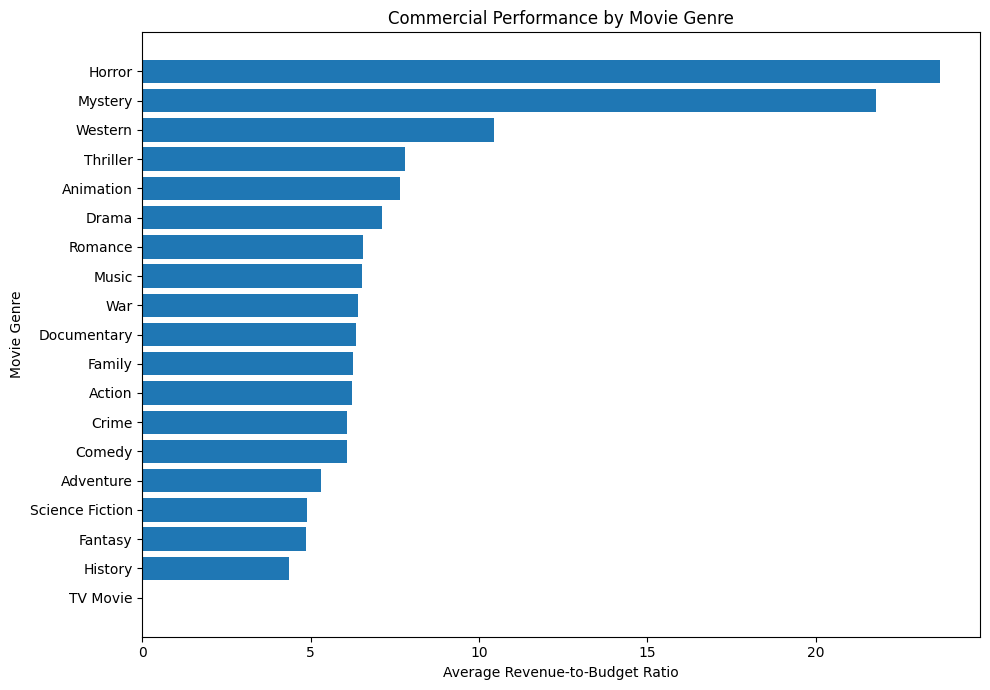

In [38]:
genre_chart = genre_summary.sort_values(
    "average_ratio", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    genre_chart["genre"],
    genre_chart["average_ratio"]
)

plt.xlabel("Average Revenue-to-Budget Ratio")
plt.ylabel("Movie Genre")
plt.title("Commercial Performance by Movie Genre")

plt.tight_layout()
plt.show()

# Audience ratings by genre

In [39]:
# Preparing genre and audience rating data

rating_data = financial_movies[
    ["title", "genres", "vote_average", "vote_count"]
].copy()

rating_data = rating_data.explode("genres")

rating_summary = (
    rating_data.groupby("genres")
    .agg(
        movie_count=("title", "nunique"),
        average_rating=("vote_average", "mean"),
        average_votes=("vote_count", "mean")
    )
    .reset_index()
    .sort_values("average_rating", ascending=False)
)

display(rating_summary.round(2))

,genres,movie_count,average_rating,average_votes
5,Documentary,5,7.32,962.80
17,War,111,7.24,4053.26
9,History,153,7.19,3100.82
18,Western,60,7.05,3203.64
6,Drama,1286,7.05,3646.43
11,Music,67,7.02,2974.09
2,Animation,239,6.96,5472.74
4,Crime,553,6.83,3606.39
13,Romance,509,6.81,3107.16
12,Mystery,298,6.74,3584.01


# Comparing audience ratings and commercial performance

In [40]:
genre_comparison = genre_summary.merge(
    rating_summary,
    left_on="genre",
    right_on="genres",
    how="inner"
)

genre_comparison = genre_comparison[
    [
        "genre",
        "movie_count_x",
        "average_ratio",
        "average_rating",
        "average_votes"
    ]
]

genre_comparison.columns = [
    "Genre",
    "Movie_Count",
    "Revenue_Budget_Ratio",
    "Average_Rating",
    "Average_Votes"
]

display(genre_comparison.round(2))

,Genre,Movie_Count,Revenue_Budget_Ratio,Average_Rating,Average_Votes
0,Horror,377,23.70,6.42,2942.35
1,Mystery,298,21.80,6.74,3584.01
2,Western,60,10.44,7.05,3203.64
3,Thriller,878,7.82,6.64,3681.06
4,Animation,239,7.66,6.96,5472.74
5,Drama,1286,7.12,7.05,3646.43
6,Romance,509,6.57,6.81,3107.16
7,Music,67,6.53,7.02,2974.09
8,War,111,6.41,7.24,4053.26
9,Documentary,5,6.33,7.32,962.80


# Testing the relationship between ratings and revenue

In [41]:
from scipy.stats import pearsonr, spearmanr

# Excluding movies without meaningful audience ratings
correlation_data = financial_movies[
    (financial_movies["vote_average"] > 0) &
    (financial_movies["vote_count"] > 0)
].copy()

# Calculating correlations
pearson_result = pearsonr(
    correlation_data["vote_average"],
    correlation_data["revenue_to_budget_ratio"]
)

spearman_result = spearmanr(
    correlation_data["vote_average"],
    correlation_data["revenue_to_budget_ratio"]
)

print("Movies analysed:", len(correlation_data))

print("\nPearson correlation:", round(pearson_result.statistic, 4))
print("Pearson p-value:", pearson_result.pvalue)

print("\nSpearman correlation:", round(spearman_result.statistic, 4))
print("Spearman p-value:", spearman_result.pvalue)

Movies analysed: 3180

Pearson correlation: 0.0167
Pearson p-value: 0.3461598838747233

Spearman correlation: 0.2889
Spearman p-value: 3.5596519388581304e-62


In [42]:
# Saving financial dataset
financial_movies.to_csv(
    f"{PROJECT_DIR}/data/processed/cinemetrix_financial_movies.csv",
    index=False
)

# Saving  genre analysis
genre_comparison.to_csv(
    f"{PROJECT_DIR}/data/processed/cinemetrix_genre_comparison.csv",
    index=False
)

# Saving correlation results
correlation_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [
        pearson_result.statistic,
        spearman_result.statistic
    ],
    "P_Value": [
        pearson_result.pvalue,
        spearman_result.pvalue
    ]
})

correlation_results.to_csv(
    f"{PROJECT_DIR}/data/processed/cinemetrix_correlation_results.csv",
    index=False
)

print("Research datasets saved successfully!")

Research datasets saved successfully!


In [43]:
import requests

url = "https://files.grouplens.org/datasets/movielens/ml-25m.zip"

zip_path = f"{PROJECT_DIR}/data/raw/movielens/ml-25m.zip"

response = requests.get(url, stream=True)
response.raise_for_status()

with open(zip_path, "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)

print("MovieLens 25M downloaded successfully!")
print("Saved at:", zip_path)

MovieLens 25M downloaded successfully!
Saved at: /content/drive/MyDrive/CINEMETRIX/data/raw/movielens/ml-25m.zip


In [44]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_file:
    for file in zip_file.namelist():
        info = zip_file.getinfo(file)
        print(file, "—", round(info.file_size / (1024 * 1024), 2), "MB")

ml-25m/ — 0.0 MB
ml-25m/tags.csv — 37.01 MB
ml-25m/links.csv — 1.31 MB
ml-25m/README.txt — 0.01 MB
ml-25m/ratings.csv — 646.84 MB
ml-25m/genome-tags.csv — 0.02 MB
ml-25m/genome-scores.csv — 415.0 MB
ml-25m/movies.csv — 2.9 MB


In [45]:
extract_dir = f"{PROJECT_DIR}/data/raw/movielens/ml-25m"

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in [
        "ml-25m/movies.csv",
        "ml-25m/links.csv",
        "ml-25m/tags.csv"
    ]:
        z.extract(filename, PROJECT_DIR + "/data/raw/movielens")

print("Smaller MovieLens files extracted!")

Smaller MovieLens files extracted!


In [46]:
ml25_movies = pd.read_csv(
    f"{PROJECT_DIR}/data/raw/movielens/ml-25m/movies.csv"
)

ml25_links = pd.read_csv(
    f"{PROJECT_DIR}/data/raw/movielens/ml-25m/links.csv"
)

ml25_tags = pd.read_csv(
    f"{PROJECT_DIR}/data/raw/movielens/ml-25m/tags.csv"
)

print("Movies:", ml25_movies.shape)
print("Links:", ml25_links.shape)
print("Tags:", ml25_tags.shape)

Movies: (62423, 3)
Links: (62423, 3)
Tags: (1093360, 4)


In [47]:
print("MOVIES")
display(ml25_movies.head(3))

print("LINKS")
display(ml25_links.head(3))

print("TAGS")
display(ml25_tags.head(3))

MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


LINKS


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


TAGS


,userId,movieId,tag,timestamp
0,3,260,classic,1439472355
1,3,260,sci-fi,1439472256
2,4,1732,dark comedy,1573943598


In [48]:
print("MOVIES")
print("Missing values:", ml25_movies.isnull().sum().sum())
print("Duplicate movie IDs:", ml25_movies["movieId"].duplicated().sum())

print("\nLINKS")
print("Missing values:", ml25_links.isnull().sum().sum())
print("Duplicate movie IDs:", ml25_links["movieId"].duplicated().sum())

print("\nTAGS")
print("Missing values:", ml25_tags.isnull().sum().sum())
print("Duplicate rows:", ml25_tags.duplicated().sum())

MOVIES
Missing values: 0
Duplicate movie IDs: 0

LINKS
Missing values: 107
Duplicate movie IDs: 0

TAGS
Missing values: 16
Duplicate rows: 0


In [49]:
ml25_movies.to_csv(
    f"{PROJECT_DIR}/data/processed/ml25_movies.csv",
    index=False
)

ml25_links.to_csv(
    f"{PROJECT_DIR}/data/processed/ml25_links.csv",
    index=False
)

ml25_tags.to_csv(
    f"{PROJECT_DIR}/data/processed/ml25_tags.csv",
    index=False
)

print("MovieLens 25M metadata saved successfully!")

MovieLens 25M metadata saved successfully!


In [50]:
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("ml-25m/ratings.csv") as file:
        ratings_sample = pd.read_csv(file, nrows=5)

display(ratings_sample)
print("Columns:", ratings_sample.columns.tolist())

,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510


Columns: ['userId', 'movieId', 'rating', 'timestamp']


In [51]:
total_ratings = 0

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("ml-25m/ratings.csv") as file:
        for chunk in pd.read_csv(file, chunksize=500_000):
            total_ratings += len(chunk)

print("Total audience ratings:", f"{total_ratings:,}")

Total audience ratings: 25,000,095


In [52]:
rating_counts = {}

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("ml-25m/ratings.csv") as file:
        for chunk in pd.read_csv(file, chunksize=500_000):
            counts = chunk["rating"].value_counts()

            for rating, count in counts.items():
                rating_counts[rating] = rating_counts.get(rating, 0) + count

rating_distribution = pd.Series(rating_counts).sort_index()

print("Rating distribution:")
display(rating_distribution.to_frame("Number of Ratings"))

Rating distribution:


,Number of Ratings
0.5,393068
1.0,776815
1.5,399490
2.0,1640868
2.5,1262797
3.0,4896928
3.5,3177318
4.0,6639798
4.5,2200539
5.0,3612474


In [53]:
rating_distribution.to_csv(
    f"{PROJECT_DIR}/data/processed/ml25_rating_distribution.csv",
    header=["rating_count"]
)

print("Rating distribution saved!")

Rating distribution saved!


In [54]:
rating_sum = 0
rating_count = 0

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("ml-25m/ratings.csv") as file:
        for chunk in pd.read_csv(file, chunksize=500_000):
            rating_sum += chunk["rating"].sum()
            rating_count += chunk["rating"].count()

overall_average = rating_sum / rating_count

print("Total ratings:", f"{rating_count:,}")
print("Overall average rating:", round(overall_average, 3))

Total ratings: 25,000,095
Overall average rating: 3.534


In [55]:
audience_overview = pd.DataFrame({
    "Metric": ["Total Ratings", "Overall Average Rating"],
    "Value": [rating_count, overall_average]
})

audience_overview.to_csv(
    f"{PROJECT_DIR}/data/processed/ml25_audience_overview.csv",
    index=False
)

display(audience_overview)
print("Audience overview saved!")

,Metric,Value
0,Total Ratings,2.500010e+07
1,Overall Average Rating,3.533854e+00


Audience overview saved!


In [56]:
audience_sample = ratings_sample.merge(
    ml25_movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

display(audience_sample)

,userId,movieId,rating,timestamp,title,genres
0,1,296,5.0,1147880044,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
1,1,306,3.5,1147868817,Three Colors: Red (Trois couleurs: Rouge) (1994),Drama
2,1,307,5.0,1147868828,Three Colors: Blue (Trois couleurs: Bleu) (1993),Drama
3,1,665,5.0,1147878820,Underground (1995),Comedy|Drama|War
4,1,899,3.5,1147868510,Singin' in the Rain (1952),Comedy|Musical|Romance


In [57]:
all_genres = sorted(
    set(
        genre
        for values in ml25_movies["genres"].dropna()
        for genre in values.split("|")
    )
)

print("Total genre categories:", len(all_genres))
print(all_genres)

Total genre categories: 20
['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
